<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat_EDAVisualization/notebooks/EDAVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Step 1 : Set up Git user**
Configuring Git with username and email for commits in this Colab environment.

In [1]:
!git config --global user.email "navishkagunawardhana@gmail.com"
!git config --global user.name "navishkaG"

# **Step 2 : Clone project repository**
Cloning the GitHub repo fake-news-detection using a personal access token and switching to that directory.


In [3]:
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"
TOKEN = "TOKEN"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}

Cloning into 'fake-news-detection'...
remote: Enumerating objects: 294, done.
remote: Counting objects: 100% (170/170), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 294 (delta 107), reused 47 (delta 43), pack-reused 124 (from 1)
Receiving objects: 100% (294/294), 2.92 MiB | 12.27 MiB/s, done.
Resolving deltas: 100% (156/156), done.
/content/fake-news-detection


# **Step 3 : Create a new feature branch**
Creating and switching to a new branch named feat_EDAVisualization for the EDA work.

In [4]:
BRANCH = "feat_EDAVisualization"
!git checkout -b {BRANCH}

Switched to a new branch 'feat_EDAVisualization'


# **Step 4 : Create required folders**
Making folders to store processed data and output figures for visualization results.

In [5]:
import os, pathlib
os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/figs", exist_ok=True)
!ls -lah data/processed

total 8.0K
drwxr-xr-x 2 root root 4.0K Oct 12 02:19 .
drwxr-xr-x 3 root root 4.0K Oct 12 02:19 ..


# **Step 5 : Upload datasets**
Uploading the train, validation, and test CSV files from the local system to Colab.

In [6]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv
Saving val.csv to val.csv


# **Step 6 : Move uploaded files**
Moving the uploaded CSVs into the data/processed folder for better organization.

In [7]:
import os
os.makedirs("data/processed", exist_ok=True)
!mv train.csv data/processed/train.csv
!mv val.csv data/processed/val.csv
!mv test.csv data/processed/test.csv
!ls data/processed

test.csv  train.csv  val.csv


# **Step 7 : Load data using pandas**
Reading the train, validation, and test CSV files into pandas DataFrames.

In [8]:
import pandas as pd

train = pd.read_csv("data/processed/train.csv")
val   = pd.read_csv("data/processed/val.csv")
test  = pd.read_csv("data/processed/test.csv")

# **Step 8 : Check expected columns**
Ensuring that the dataset contains the required columns: text_clean and label.

In [9]:
assert {'text_clean','label'}.issubset(train.columns), "Expected columns: text_clean, label"
train.head()

,text_clean,label
0,kenya police shoot dead two opposition protest...,0
1,angry cruz kicks young boy rally disruptive su...,1
2,region must pressure south sudan leaders end c...,0
3,names revealed top donor popular actress behin...,1
4,holy moly rebel media uncovers illegal usa can...,1


# **Step 9 : Label distribution visualization**
Checking dataset sizes and visualizing label distribution in training data.

In [10]:
import matplotlib.pyplot as plt

Shapes → train: (37554, 2)  val: (4489, 3)  test: (4489, 3)

Label distribution (train):
label
real    0.5
fake    0.5
Name: proportion, dtype: float64


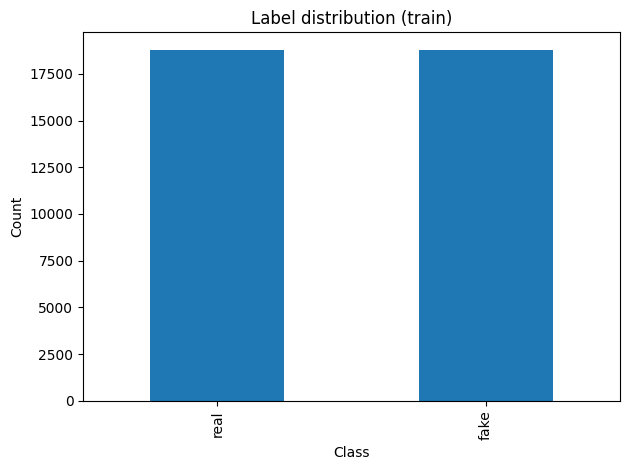

In [11]:
print("Shapes → train:", train.shape, " val:", val.shape, " test:", test.shape)
print("\nLabel distribution (train):")
print(train['label'].value_counts(normalize=True).rename({0:'real',1:'fake'}))

# Save a bar chart of label distribution
ax = train['label'].replace({0:'real',1:'fake'}).value_counts().plot(kind='bar')
plt.title('Label distribution (train)')
plt.xlabel('Class'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('results/figs/label_dist_train.png'); plt.show()

# **Step 10 : Analyze text lengths**
Adding a token length column to see how long each news article is and plotting a histogram.

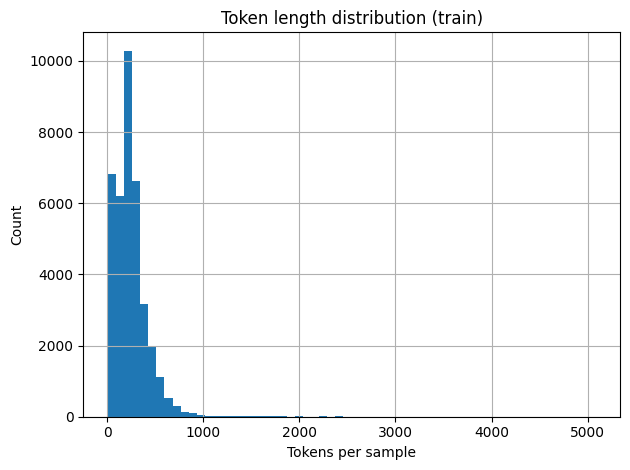

Length stats: count    37554.000000
mean       248.903712
std        207.836074
min          4.000000
50%        221.000000
90%        454.000000
95%        553.350000
99%        879.470000
max       5083.000000
Name: len, dtype: float64


In [12]:
train['len'] = train['text_clean'].str.split().apply(len)

# Histogram (token lengths)
train['len'].hist(bins=60)
plt.title('Token length distribution (train)')
plt.xlabel('Tokens per sample'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('results/figs/len_hist_train.png'); plt.show()

print("Length stats:", train['len'].describe(percentiles=[.5,.9,.95,.99]))

# **Step 11 : Generate word clouds**
Creating word clouds to visualize frequent words in real vs fake news samples.

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

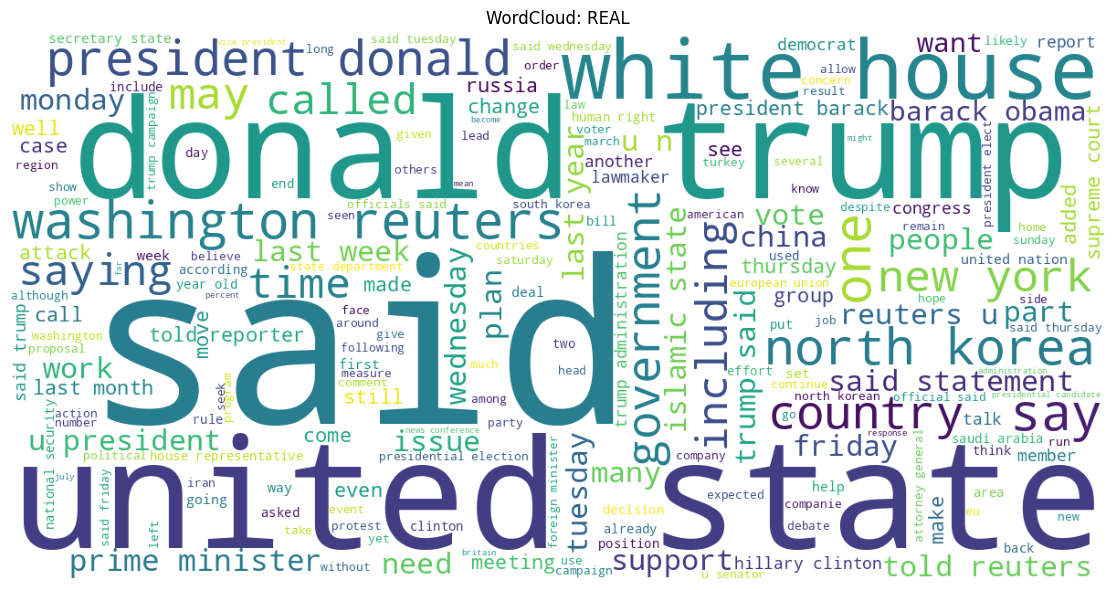

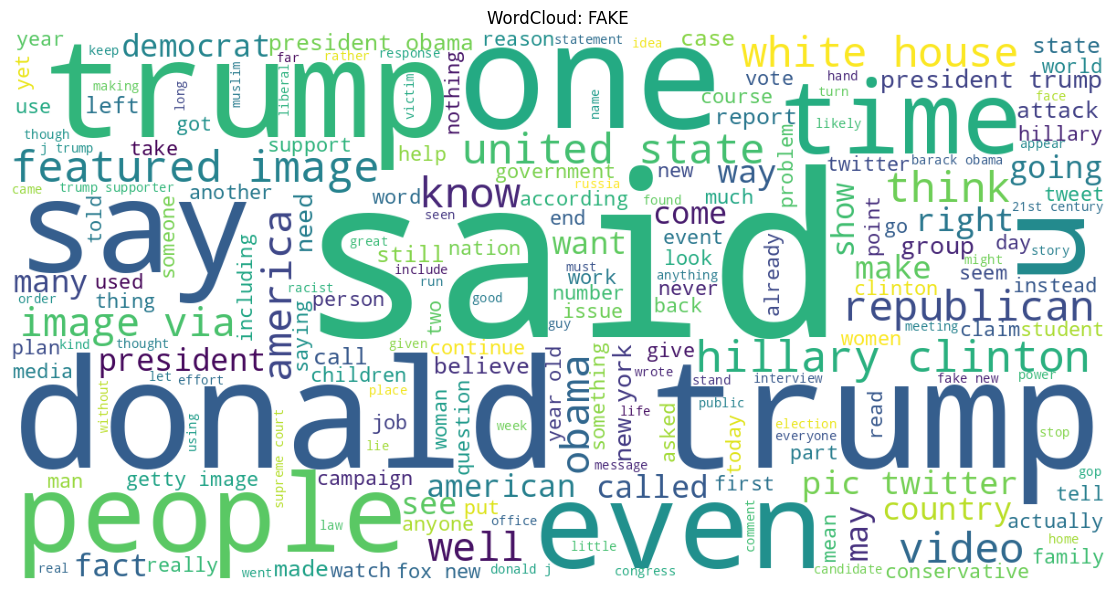

In [14]:
def plot_wc(texts, title, outfile):
  # Joining all texts into one string and generating a word cloud
    txt = " ".join(texts.tolist())
    wc = WordCloud(width=1200, height=600, background_color='white').generate(txt)
    plt.figure(figsize=(12,6))
    plt.imshow(wc); plt.axis('off'); plt.title(title)
    plt.tight_layout()
    plt.savefig(outfile); plt.show()

# Word clouds for real and fake labels
plot_wc(train[train['label']==0]['text_clean'], "WordCloud: REAL", 'results/figs/wc_real.png')
plot_wc(train[train['label']==1]['text_clean'], "WordCloud: FAKE", 'results/figs/wc_fake.png')

# **Step 12 : Find top n-grams**
Extracting and displaying top unigrams, bigrams, and trigrams using CountVectorizer.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

Top unigrams: [('trump', np.int64(123767)), ('said', np.int64(113684)), ('president', np.int64(48389)), ('would', np.int64(46874)), ('people', np.int64(35240)), ('one', np.int64(32025)), ('state', np.int64(29943)), ('new', np.int64(27874)), ('also', np.int64(26329)), ('obama', np.int64(26023))]
Top bigrams: [('donald trump', np.int64(22665)), ('united states', np.int64(16065)), ('white house', np.int64(13643)), ('hillary clinton', np.int64(8445)), ('new york', np.int64(7812)), ('north korea', np.int64(6362)), ('featured image', np.int64(6110)), ('president donald', np.int64(6065)), ('washington reuters', np.int64(5840)), ('image via', np.int64(5066))]
Top trigrams: [('president donald trump', np.int64(6005)), ('pic twitter com', np.int64(4885)), ('featured image via', np.int64(4516)), ('president barack obama', np.int64(3361)), ('new york times', np.int64(1752)), ('21st century wire', np.int64(1534)), ('donald trump realdonaldtrump', np.int64(1440)), ('reuters president donald', np.int

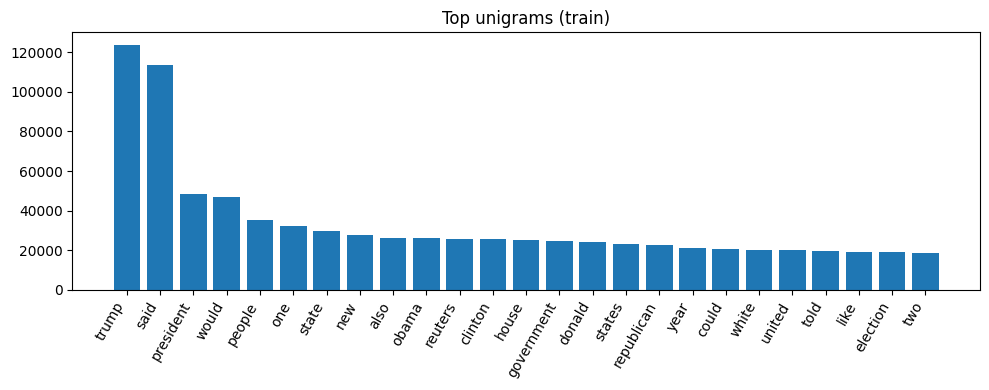

In [16]:
def top_ngrams(texts, ngram=(1,1), topk=25, min_df=5):
    vec = CountVectorizer(ngram_range=ngram, min_df=min_df).fit(texts)
    bag = vec.transform(texts)
    sums = np.asarray(bag.sum(axis=0)).ravel()
    idx = np.argsort(-sums)[:topk]
    vocab = np.array(vec.get_feature_names_out())
    return list(zip(vocab[idx], sums[idx]))

# Getting top unigrams, bigrams, and trigrams
uni = top_ngrams(train['text_clean'], (1,1), 25, 5)
bi  = top_ngrams(train['text_clean'], (2,2), 25, 5)
tri = top_ngrams(train['text_clean'], (3,3), 15, 5)

print("Top unigrams:", uni[:10])
print("Top bigrams:", bi[:10])
print("Top trigrams:", tri[:10])

# Save top unigrams as a simple bar plot
labels, counts = zip(*uni)
plt.figure(figsize=(10,4))
plt.bar(range(len(labels)), counts)
plt.xticks(range(len(labels)), labels, rotation=60, ha='right')
plt.title('Top unigrams (train)')
plt.tight_layout()
plt.savefig('results/figs/top_unigrams.png'); plt.show()

# **Step 13 : Save summary statistics**
Creating a small summary (dataset size, ratios, lengths) and saving as a CSV file.

In [17]:
summary = {
    "n_train": len(train),
    "n_val": len(val),
    "n_test": len(test),
    "pos_ratio_train": float((train['label']==1).mean()),
    "median_len": int(train['len'].median()),
    "p90_len": int(train['len'].quantile(0.90)),
}
pd.DataFrame([summary])

,n_train,n_val,n_test,pos_ratio_train,median_len,p90_len
0,37554,4489,4489,0.5,221,454


In [18]:
# Exporting the summary as CSV
summary_df = pd.DataFrame([summary])
summary_df.to_csv('results/eda_summary.csv', index=False)
print("Saved: results/eda_summary.csv")

Saved: results/eda_summary.csv


# **Step 14 : Commit and push results to GitHub**
Adding all generated results and figures to Git, committing, and pushing to the new branch.

In [19]:
!git add -f results/eda_summary.csv \
results/figs/label_dist_train.png \
results/figs/len_hist_train.png \
results/figs/top_unigrams.png \
results/figs/wc_real.png \
results/figs/wc_fake.png

!git commit -m "Add of summary & figures"
!git push --set-upstream origin feat_EDAVisualization

[feat_EDAVisualization fd6c247] Add of summary & figures
 2 files changed, 0 insertions(+), 0 deletions(-)
 rewrite results/figs/wc_fake.png (93%)
 rewrite results/figs/wc_real.png (93%)
fatal: could not read Password for 'https://TOKEN@github.com': No such device or address
